# ARC-AGI-2: Object-Centric Perception & Relational Reasoning

This notebook demonstrates the object-centric perception, scene graph construction, and cross-example relational change analysis subsystems of our ARC-AGI-2 neuro-symbolic research solver.

### Pipeline Subsystems Demonstrated:
1. **Canonical Grid Representation & Color Palette**: Handling rectangular ARC grids and exact discrete colors.
2. **Deterministic Object Perception**: Inferring background colors, 4-connected vs 8-connected component segmentation, and shape classification.
3. **Perception Hypotheses**: Generating competing interpretations (monochromatic, multi-color, partition).
4. **Relational Scene Graphs**: Constructing directed attributed multigraphs encoding spatial relations (`above`, `below`, `contains`, `same_color`, `larger_than`).
5. **Cross-Demonstration Invariants**: Detecting shape preservation, consistent recolor mappings, and movement vectors across training demonstrations.


In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# Add repository root to python path
repo_root = Path("..").resolve()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.data.dataset_loader import ArcDatasetLoader
from src.representation.grid import ArcGrid
from src.perception.detector import PerceptionEngine, infer_background_color
from src.perception.hypotheses import PerceptionHypothesisGenerator
from src.scene_graph.builder import SceneGraphBuilder
from src.correspondence.matcher import ObjectCorrespondenceMatcher
from src.correspondence.relational_change import RelationalChangeAnalyzer
from src.visualization import plot_grid, plot_task, ARC_COLORS

print("All perception and reasoning modules successfully imported.")


/home/naya/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


All perception and reasoning modules successfully imported.


## 1. Loading and Visualizing an ARC Task

We load task `007bbfb7` from the training dataset. This task features 3x3 pattern demonstration grids and test inputs.


Loaded Task: 007bbfb7 | Demonstrations: 5 | Test Inputs: 1


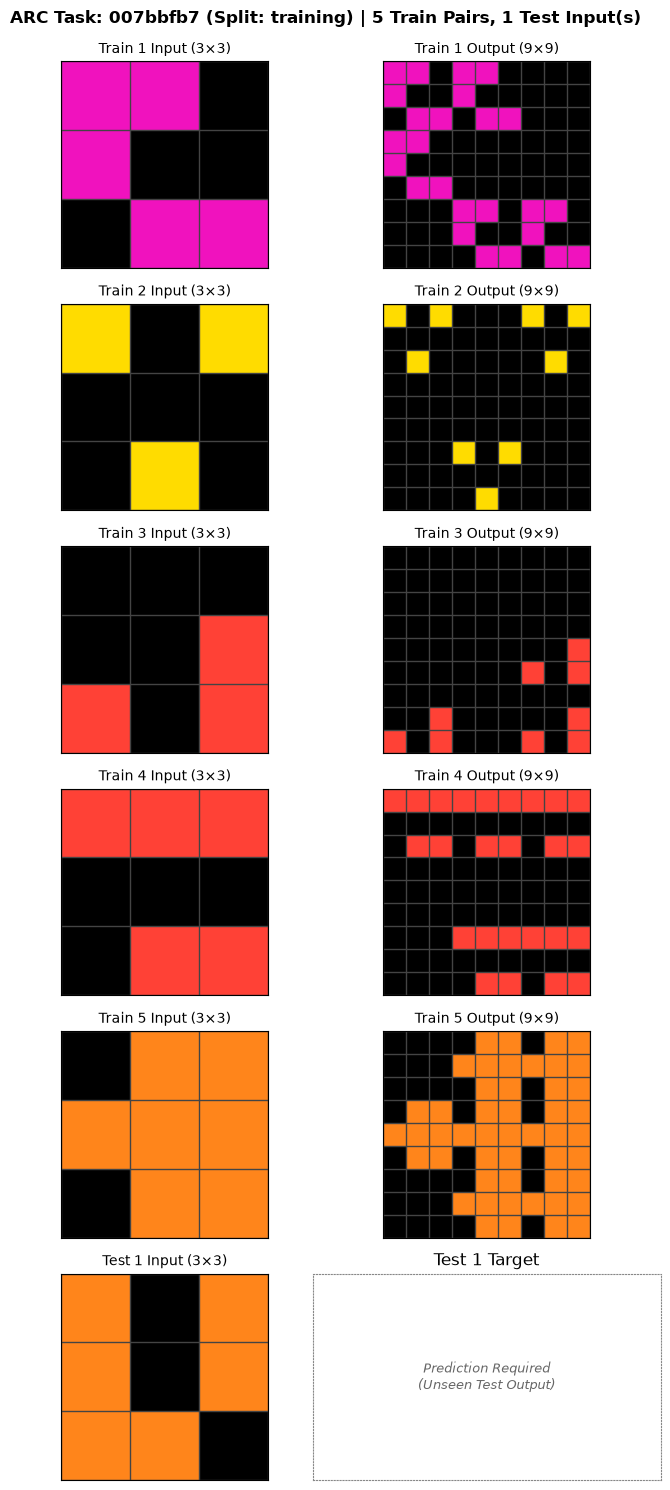

In [2]:
loader = ArcDatasetLoader(data_dir=repo_root / "data" / "raw")
task = loader.load_task("007bbfb7")

print(f"Loaded Task: {task.task_id} | Demonstrations: {len(task.train_examples)} | Test Inputs: {len(task.test_inputs)}")
plot_task(task)
plt.show()


## 2. Object-Centric Perception & Competing Hypotheses

Instead of forcing an arbitrary single segmentation, the solver constructs competing hypotheses:
- `mono_4conn`: Monochromatic 4-connected components (canonical ARC prior).
- `mono_8conn`: Monochromatic 8-connected components (diagonal touches).
- `color_partition`: Color-separated regions.
- `multicolor_4conn`: Multi-color connected blocks.


In [3]:
engine = PerceptionEngine()
hypo_gen = PerceptionHypothesisGenerator(engine)

first_demo_input = ArcGrid(np_grid=task.train_examples[0].input_grid)
bg_color = infer_background_color(first_demo_input)
print(f"Inferred Background Color: {bg_color}")

hypotheses = hypo_gen.generate_hypotheses(first_demo_input)
for h in hypotheses:
    print(f"Hypothesis: {h.name:<18} | Confidence: {h.confidence:.2f} | Objects: {len(h.objects)}")
    for obj in h.objects:
        print(f"  - Obj ID: {obj.object_id} | Color: {obj.color} | Area: {obj.area} | Shape: {obj.shape_type} | BBox: {obj.bbox}")


Inferred Background Color: 0
Hypothesis: mono_4conn         | Confidence: 0.85 | Objects: 2
  - Obj ID: 1 | Color: 6 | Area: 3 | Shape: irregular | BBox: BoundingBox(min_row=0, min_col=0, max_row=1, max_col=1)
  - Obj ID: 2 | Color: 6 | Area: 2 | Shape: h_line | BBox: BoundingBox(min_row=2, min_col=1, max_row=2, max_col=2)
Hypothesis: mono_8conn         | Confidence: 0.70 | Objects: 1
  - Obj ID: 1 | Color: 6 | Area: 5 | Shape: irregular | BBox: BoundingBox(min_row=0, min_col=0, max_row=2, max_col=2)
Hypothesis: color_partition    | Confidence: 0.55 | Objects: 1
  - Obj ID: 1 | Color: 6 | Area: 5 | Shape: irregular | BBox: BoundingBox(min_row=0, min_col=0, max_row=2, max_col=2)
Hypothesis: multicolor_4conn   | Confidence: 0.40 | Objects: 2
  - Obj ID: 1 | Color: 6 | Area: 3 | Shape: irregular | BBox: BoundingBox(min_row=0, min_col=0, max_row=1, max_col=1)
  - Obj ID: 2 | Color: 6 | Area: 2 | Shape: h_line | BBox: BoundingBox(min_row=2, min_col=1, max_row=2, max_col=2)


## 3. Structural Scene Graph Representation

We convert perceived objects into a directed attributed scene graph capturing pairwise spatial relationships:
- Spatial: `above`, `below`, `left_of`, `right_of`
- Containment: `contains`, `inside`
- Equivalence: `same_color`, `same_shape`, `equal_area`
- Magnitude: `larger_than`, `smaller_than`


In [4]:
builder = SceneGraphBuilder()
objects = engine.segment_monochromatic_connected_components(first_demo_input, background_color=bg_color)
scene_graph = builder.build(first_demo_input, objects, background_color=bg_color)

print(scene_graph.summary())


SceneGraph (Shape: (3, 3), Bg: 0, Nodes: 2, Edges: 6)
  Node 1: color=6, shape=irregular, area=3, centroid=(0.3333333333333333, 0.3333333333333333)
  Node 2: color=6, shape=h_line, area=2, centroid=(2.0, 1.5)
  Edge: (1) --[above]--> (2)
  Edge: (2) --[below]--> (1)
  Edge: (1) --[same_color]--> (2)
  Edge: (2) --[same_color]--> (1)
  Edge: (1) --[larger_than]--> (2)
  Edge: (2) --[smaller_than]--> (1)


## 4. Cross-Demonstration Relational Change Analysis

The `RelationalChangeAnalyzer` examines all training demonstrations collectively to identify invariant transformation rules.


In [5]:
from src.search.verifier import TaskDemonstration

demonstrations = [
    TaskDemonstration(ArcGrid(np_grid=ex.input_grid), ArcGrid(np_grid=ex.output_grid))
    for ex in task.train_examples
]

analyzer = RelationalChangeAnalyzer()
change_report = analyzer.analyze_task(demonstrations)

print("=== Task Invariant Analysis ===")
print(f"Preserves Dimensions: {change_report.preserves_dimensions}")
print(f"Consistent Scale Factor: {change_report.scale_factor}")
print(f"Consistent Color Map: {change_report.consistent_color_map}")
print(f"Consistent Movement: {change_report.consistent_movement}")
print(f"Hypothesized Transformations: {change_report.hypothesized_transformations}")


=== Task Invariant Analysis ===
Preserves Dimensions: False
Consistent Scale Factor: (3.0, 3.0)
Consistent Color Map: {2: 2, 4: 4, 6: 6}
Consistent Movement: None
Hypothesized Transformations: ['tile_or_scale_3']
